# 07 · Parameters

Part 3 of the study plan (`docs/study_plan.md`): realistic bounds for the model's parameters and the poll input of the
empirical mode, from the polls. Nothing here runs the model. Blocks: **poll noise ρ<sub>s</sub> and temperature θ**,
then prior spread ρ<sub>π</sub>, tolerance (paired scenarios), real-world ranges for the synthetic setup, and the
empirical poll input.

The ABM's synthetic poll (docs/model.md, *Generated polls*): s̃<sub>i</sub> ∝ (δ<sub>i</sub> + ε)<sup>1/θ</sup>, then
s ~ Dirichlet(ρ<sub>s</sub> · s̃). Current Saltelli bounds: θ ∈ [0.3, 3], ρ<sub>s</sub> ∈ [10, 200]
(`analysis/synthetic/parameter_space.py`).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from polls import average, metrics, timeline

pd.set_option("display.width", 200)
TABLES, FIGURES = ROOT / "results" / "tables", ROOT / "results" / "figures"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})
BOUNDS = {"theta": (0.3, 3.0), "rho_s": (10.0, 200.0), "rho_pi": (5.0, 200.0)}

calendar = timeline.load(ROOT / "config" / "elections.yaml")
rows = timeline.add_time(pd.read_csv(ROOT / "data" / "final" / "polls.csv", low_memory=False), calendar)
results = pd.read_csv(ROOT / "data" / "interim" / "results.csv")
ELECTIONS = sorted(rows["election"].unique())
b = rows[rows["ballot_scenario"] & (rows["share_status"] != "not_tested")].copy()
b["value"] = np.where(b["share_status"] == "value", b["share"], b["share_upper_bound"] * 0.5)
slot_vals = b[b["slot"].notna()].groupby(["election", "poll_id", "slot"]).agg(
    value=("value", "sum"), days_before=("days_before", "first"), phase=("phase", "first")).reset_index()
core = results[results["share"] >= 2.0].rename(columns={"candidate": "slot", "share": "result"})[["election", "slot", "result"]]

## 1 · Poll noise ρ<sub>s</sub>

Since Var(s<sub>i</sub>) = s<sub>i</sub>(1 − s<sub>i</sub>)/(ρ<sub>s</sub> + 1), ρ<sub>s</sub> = *n*<sub>eff</sub> − 1, with
*n*<sub>eff</sub> = mean *p*(100 − *p*) / mean squared deviation (shares in points). Three readings:

- **single poll**: the scatter of one poll around the poll average (notebook 05, section 5): what one poll adds as noise;
- **weekly average**: a voter reading the mean of a week's polls; if the polls of a week were independent, its
  *n*<sub>eff</sub> would be the single-poll one times the polls per week (herding makes them less independent, so this is
  an upper bound);
- **total**: the poll average a week before the vote against the result, core candidates: noise, pollsters' common
  bias and real late movement together (a lower bound).

In [2]:
noise = pd.read_csv(TABLES / "noise_effective_sample_size.csv")
single = noise.pivot(index="election", columns="period", values="n_eff")
per_week = (slot_vals.drop_duplicates("poll_id").assign(w=lambda d: d["days_before"] <= 28)
            .query("w").groupby("election")["poll_id"].nunique() / 4)

avg7 = pd.concat([average.by_candidate(g, "value", np.array([7])).assign(election=e)
                  for e, g in slot_vals.groupby("election")], ignore_index=True).dropna(subset=["mean"])
tot = avg7.merge(core)
tot["sq"] = (tot["result"] - tot["mean"]) ** 2
tot["pq"] = tot["mean"] * (100 - tot["mean"])
total = tot.groupby("election").apply(lambda g: g["pq"].mean() / g["sq"].mean(), include_groups=False)

rho = pd.DataFrame({
    "single poll, campaign": single["last 12 months"] - 1,
    "single poll, last two weeks": single["last two weeks"] - 1,
    "polls per week, last 4 weeks": per_week,
    "weekly average, last 4 weeks (upper bound)": single["last two weeks"] * per_week - 1,
    "total, 1 week before vs result (lower bound)": total - 1,
})
rho.round(0).to_csv(TABLES / "parameters_rho_s.csv")
print(f"Current bounds for ρ_s: {BOUNDS['rho_s']}")
rho.round(0)

Current bounds for ρ_s: (10.0, 200.0)


,"single poll, campaign","single poll, last two weeks","polls per week, last 4 weeks","weekly average, last 4 weeks (upper bound)","total, 1 week before vs result (lower bound)"
election,,,,,
2002,876.0,934.0,6.0,5377.0,180.0
2007,491.0,1003.0,8.0,8030.0,322.0
2012,843.0,1072.0,6.0,6708.0,456.0
2017,752.0,1813.0,10.0,17683.0,728.0
2022,780.0,890.0,15.0,13369.0,101.0


## 2 · Temperature θ

**(A) Candidate by candidate.** For the core candidates (≥ 2% in the result), log(polled share) against log(result
share), with the polled share the mean of the last two weeks: slope = 1/θ. Over each election, and over each poll of
the last two weeks (its distribution). θ < 1: polls exaggerate the gaps; θ > 1: they flatten them.

**(B) Shape only.** Shares sorted, log share against log rank, in the last-two-weeks poll average and in the result:
θ = slope<sub>result</sub> / slope<sub>polls</sub>. It compares how steeply support falls with rank, whoever holds each
rank, so it is not affected by candidates swapping places.

Both treat the result as the true support. The result also contains the late switching the model is meant to produce,
so θ measured here mixes poll distortion with that switching.

In [3]:
last = slot_vals[slot_vals["phase"] == timeline.PHASES[2]]
lp = last.groupby(["election", "slot"])["value"].mean().rename("polled").reset_index().merge(core)

def slope_a(d):
    return np.polyfit(np.log(d["result"]), np.log(d["polled"]), 1)[0]

def slope_b(shares):
    s = np.sort(np.asarray(shares, float))[::-1]
    return np.polyfit(np.log(np.arange(1, len(s) + 1)), np.log(s), 1)[0]

rng = np.random.default_rng(7)
theta = []
for e in ELECTIONS:
    d = lp[lp["election"] == e]
    per_poll = []
    for pid, g in last[last["election"] == e].groupby("poll_id"):
        g = g.merge(core)
        if len(g) >= 4:
            per_poll.append(1 / np.polyfit(np.log(g["result"]), np.log(g["value"]), 1)[0])
    # bootstrap over the polls of the last two weeks
    pids = last[last["election"] == e]["poll_id"].unique()
    boots_a, boots_b = [], []
    for _ in range(1000):
        sel = last[last["poll_id"].isin(rng.choice(pids, len(pids)))]
        m = sel.groupby("slot")["value"].mean().rename("polled").reset_index().merge(core[core["election"] == e])
        boots_a.append(1 / slope_a(m))
        boots_b.append(slope_b(core[core["election"] == e]["result"]) / slope_b(m["polled"]))
    theta.append(dict(election=e, candidates=len(d),
                      theta_A=1 / slope_a(d), theta_A_low=np.percentile(boots_a, 2.5), theta_A_high=np.percentile(boots_a, 97.5),
                      theta_A_single_polls_median=np.median(per_poll),
                      theta_A_single_polls_p10=np.percentile(per_poll, 10), theta_A_single_polls_p90=np.percentile(per_poll, 90),
                      theta_B=slope_b(core[core["election"] == e]["result"]) / slope_b(d["polled"]),
                      theta_B_low=np.percentile(boots_b, 2.5), theta_B_high=np.percentile(boots_b, 97.5)))
theta = pd.DataFrame(theta).set_index("election")
theta.round(3).to_csv(TABLES / "parameters_theta.csv")
print(f"Current bounds for θ: {BOUNDS['theta']}")
theta.round(2)

Current bounds for θ: (0.3, 3.0)


,candidates,theta_A,theta_A_low,theta_A_high,theta_A_single_polls_median,theta_A_single_polls_p10,theta_A_single_polls_p90,theta_B,theta_B_low,theta_B_high
election,,,,,,,,,,
2002,13,1.00,0.97,1.03,0.97,0.93,1.10,0.95,0.92,0.98
2007,6,0.94,0.91,0.97,0.93,0.82,1.06,1.00,0.96,1.03
2012,6,1.03,0.99,1.06,1.05,0.91,1.14,1.06,1.03,1.09
2017,6,0.98,0.97,0.99,0.97,0.95,1.01,0.97,0.96,0.98
2022,9,1.12,1.11,1.14,1.12,1.02,1.22,1.08,1.07,1.10


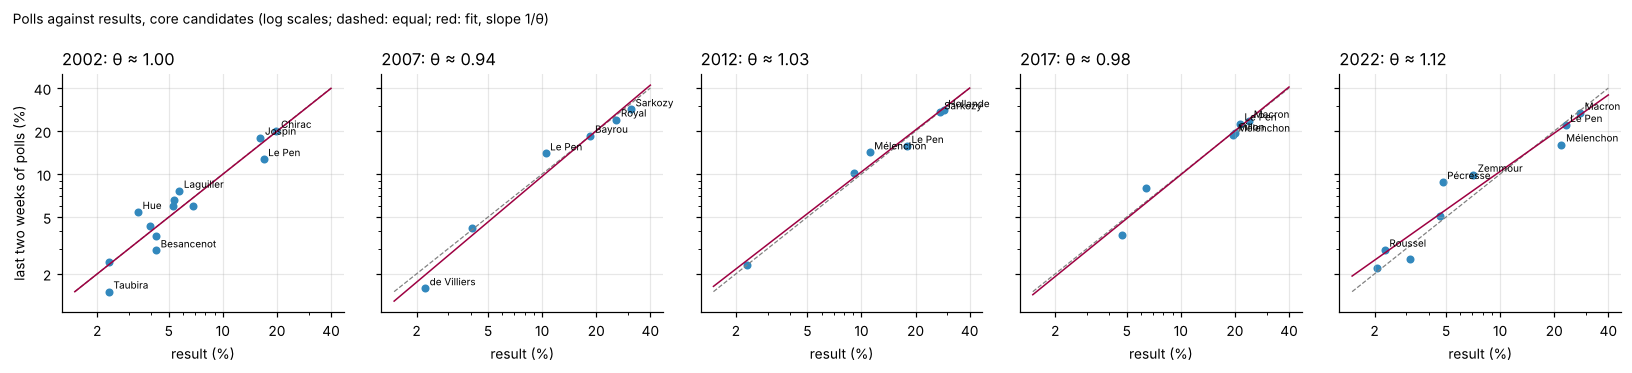

In [4]:
fig, axes = plt.subplots(1, len(ELECTIONS), figsize=(15, 3.4), sharex=True, sharey=True)
for ax, e in zip(axes, ELECTIONS):
    d = lp[lp["election"] == e]
    ax.scatter(d["result"], d["polled"], s=18, color="#3288bd")
    for r in d.itertuples():
        if r.result >= 10 or abs(np.log(r.polled / r.result)) > 0.25:
            ax.annotate(r.slot.split(" ", 1)[1], (r.result, r.polled), fontsize=6.5, xytext=(3, 2), textcoords="offset points")
    lim = np.array([1.5, 40])
    ax.plot(lim, lim, color="grey", lw=0.8, ls="--")
    ax.plot(lim, np.exp(np.polyval(np.polyfit(np.log(d["result"]), np.log(d["polled"]), 1), np.log(lim))), color="#9e0142", lw=1)
    ax.set_xscale("log"); ax.set_yscale("log")
    for axis in (ax.xaxis, ax.yaxis):
        axis.set_major_locator(plt.FixedLocator([2, 5, 10, 20, 40]))
        axis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))
        axis.set_minor_formatter(plt.NullFormatter())
    ax.set_title(f"{e}: θ ≈ {theta.loc[e, 'theta_A']:.2f}", loc="left")
    ax.set_xlabel("result (%)")
axes[0].set_ylabel("last two weeks of polls (%)")
fig.suptitle("Polls against results, core candidates (log scales; dashed: equal; red: fit, slope 1/θ)", x=0.01, ha="left", fontsize=9)
fig.tight_layout()
fig.savefig(FIGURES / "parameters_theta.png")